# 🏙️ Notebook 06.1: Clustering Data Pipeline
## Objective
Isolate the 5 physical characteristics of the properties, identify extreme structural outliers, mathematically standardize the data, and export it for our Unsupervised Learning models.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import joblib
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')

### 1. Load & Engineer Data

In [2]:
train = pd.read_csv('../../data/raw/train.csv')
train['TotalSF'] = train['TotalBsmtSF'] + train['1stFlrSF'] + train['2ndFlrSF']

cluster_features = ['TotalSF', 'OverallQual', 'YearBuilt', 'LotArea', 'GarageCars']
train = train.dropna(subset=cluster_features + ['SalePrice']).copy()

### 2. Outlier Detection (Box Plots)
Before clustering, we must inspect the features for extreme outliers. Distance-based algorithms (like K-Means and Hierarchical Clustering) are highly sensitive to massive outliers.

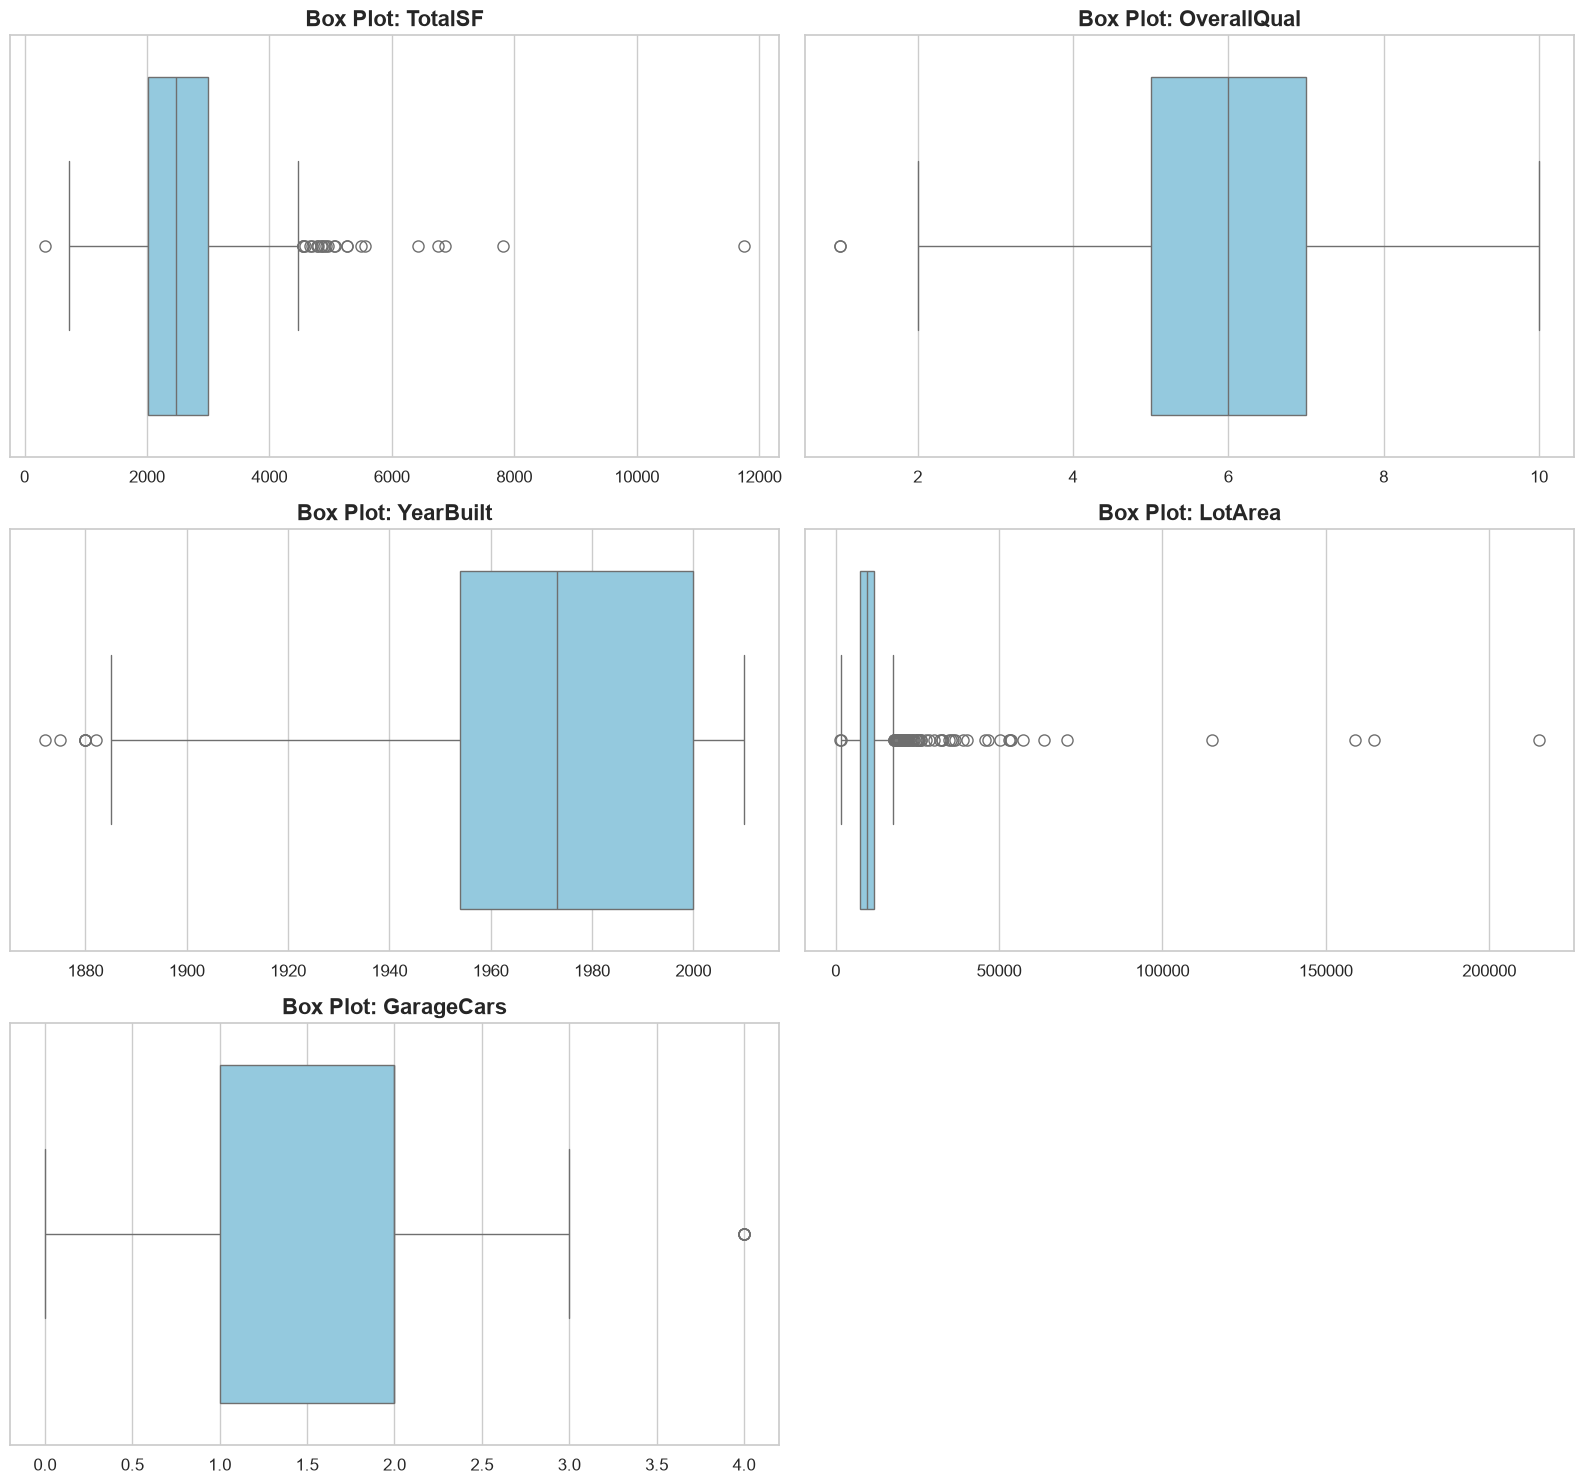

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
axes = axes.flatten()

for i, feature in enumerate(cluster_features):
    sns.boxplot(x=train[feature], ax=axes[i], color='skyblue', fliersize=8)
    axes[i].set_title(f'Box Plot: {feature}', fontsize=16, fontweight='bold')
    axes[i].tick_params(labelsize=12)
    axes[i].set_xlabel('')

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

### 3. Outlier Strategy (The Discovery Method)
As seen in the Box Plots, `LotArea` has a few properties pushing past 100,000+ sq ft (nearly 4 acres). Instead of manually deleting them now, we will pass the full dataset to our Unsupervised Learning algorithms to see if the AI can natively detect and isolate these rural anomalies!

In [4]:
print(f"Shape passed to models: {train.shape}")

X_raw = train[cluster_features]
y_price = train['SalePrice']

Shape passed to models: (1460, 82)


### 4. Scaling (Standardization)
We must scale `LotArea` (10,000+) so it doesn't mathematically crush features with smaller scales like `GarageCars` (1-4).

In [5]:
scaler = StandardScaler()
X_scaled_data = scaler.fit_transform(X_raw)
X_scaled = pd.DataFrame(X_scaled_data, columns=X_raw.columns, index=X_raw.index)

### 5. Export the Pipeline Data

In [6]:
# Save datasets
X_raw.to_csv('../../data/processed/X_cluster_raw.csv', index=False)
X_scaled.to_csv('../../data/processed/X_cluster_scaled.csv', index=False)
y_price.to_csv('../../data/processed/y_cluster_price.csv', index=False)

# Save the scaler for the web app
joblib.dump(scaler, '../../models/tier_scaler.pkl')
print('Data Prep Complete. Files exported.')

Data Prep Complete. Files exported.
